In [ ]:
import matplotlib.pyplot as plt
import matplotlib
# Set font size and family for the entire figure
matplotlib.rcParams['font.size'] = 12
matplotlib.rcParams['font.family'] = 'serif'

In [ ]:
import pandas as pd
from google.colab import drive

# Mount Google Drive
drive.mount('/content/drive')


Mounted at /content/drive


## 1 · Setup

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.neighbors import NearestNeighbors
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.metrics import (
    silhouette_score, davies_bouldin_score, calinski_harabasz_score,   # internal
    adjusted_rand_score, normalized_mutual_info_score,                 # external
    homogeneity_completeness_v_measure,
)

RANDOM_STATE = 42
plt.rcParams["figure.figsize"] = (7, 4.5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.25

## **2 · Connect to Dataset**

In [ ]:
dataset_link = "/content/drive/MyDrive/Machine Learning Lab/ecommerce_customers.csv"
df = pd.read_csv(dataset_link)

In [ ]:
df.shape

(680, 6)

## 3 · About the dataset

An **e-commerce company** has behavioural data on its customers. We synthesise it so we *know* the
true segments (useful for scoring later), but the structure mimics real data, overlapping ranges, mixed scales,
and a handful of genuine **outliers** (data-entry errors / bots) that do not belong to any segment.

Five features per customer:

| Feature | Meaning | Scale |
|---|---|---|
| `age` | years | 18–75 |
| `annual_income_k` | annual income, \$000 | 10–200 |
| `spending_score` | in-house 0–100 spending index | 1–100 |
| `web_sessions_mo` | site visits per month | 0–80 |
| `avg_purchase_usd` | average order value, \$ | 5–400 |

Four real segments plus injected outliers.

## 4 · Explore the data

In [ ]:
print(df["true_segment"].value_counts(), "\n")
df.describe().round(1)

true_segment
Premium Loyalists       180
Budget Conscious        170
Young Trend Shoppers    160
Affluent Infrequent     150
Outlier                  20
Name: count, dtype: int64 



,age,annual_income_k,spending_score,web_sessions_mo,avg_purchase_usd
count,680.0,680.0,680.0,680.0,680.0
mean,40.3,66.3,53.5,21.8,74.7
std,11.8,28.1,28.0,15.1,47.8
min,18.0,10.7,7.0,2.0,15.0
25%,29.0,40.3,26.0,8.0,32.8
50%,41.0,60.8,67.0,21.0,69.2
75%,49.0,91.2,81.0,32.0,111.9
max,75.0,184.3,98.0,77.0,371.5


The features live on very different scales (income in the tens, sessions in single digits). Distance-based
clustering would let `annual_income_k` dominate, so **standardisation in the next step is essential.**

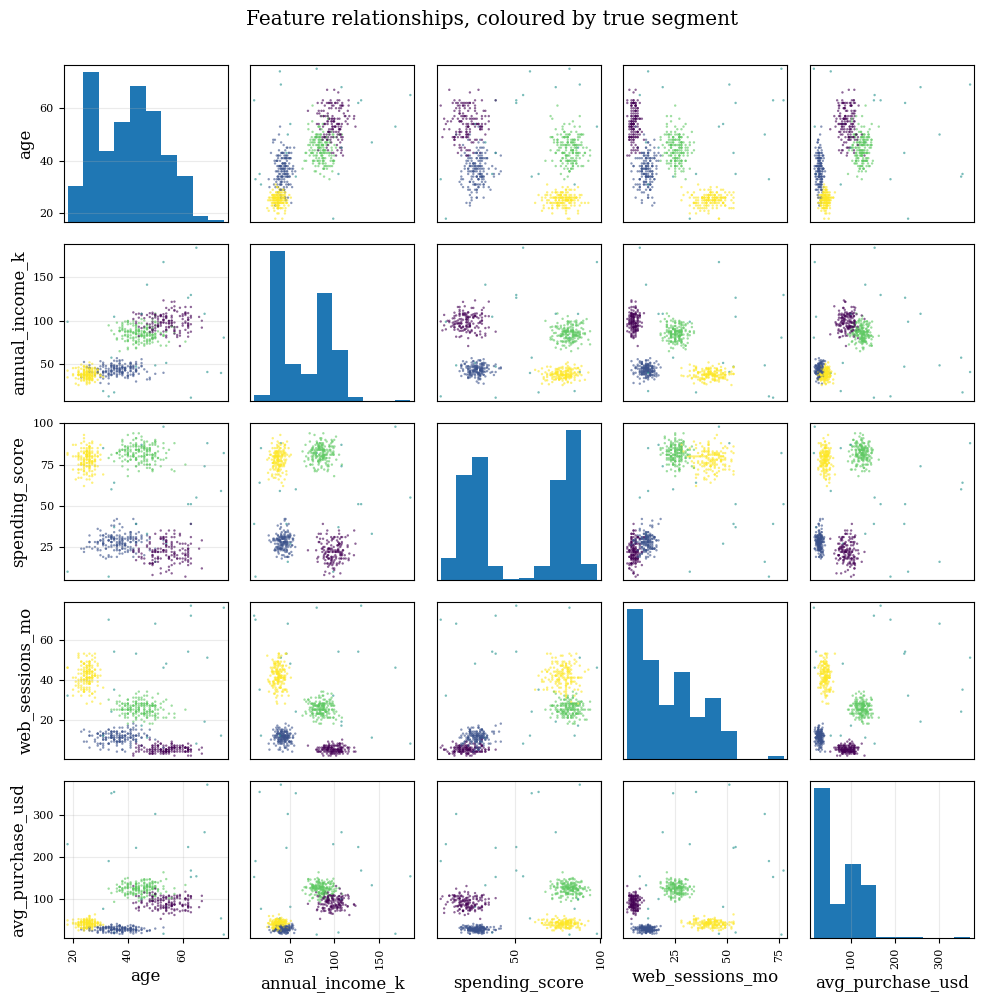

In [ ]:
features = ["age", "annual_income_k", "spending_score", "web_sessions_mo", "avg_purchase_usd"]

# scatter-matrix coloured by the true segment (for intuition only)
codes = df["true_segment"].astype("category").cat.codes
axes = pd.plotting.scatter_matrix(df[features], c=codes, figsize=(10, 10),
                                  diagonal="hist", alpha=0.6, s=12)
plt.suptitle("Feature relationships, coloured by true segment", y=1.0)
plt.tight_layout(); plt.show()

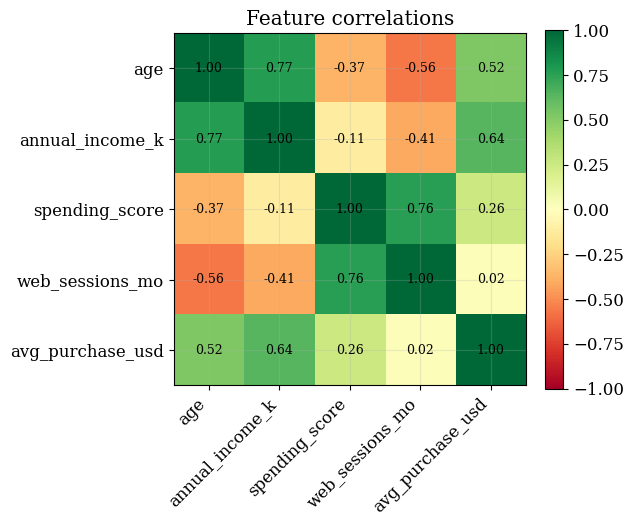

In [ ]:
# correlation heatmap
corr = df[features].corr()
fig, ax = plt.subplots(figsize=(6.5, 9.5))
im = ax.imshow(corr, cmap="RdYlGn", vmin=-1, vmax=1)
ax.set_xticks(range(len(features))); ax.set_xticklabels(features, rotation=45, ha="right")
ax.set_yticks(range(len(features))); ax.set_yticklabels(features)
for i in range(len(features)):
    for j in range(len(features)):
        ax.text(j, i, f"{corr.iloc[i,j]:.2f}", ha="center", va="center", fontsize=9)
plt.colorbar(im, fraction=0.046); plt.title("Feature correlations"); plt.tight_layout(); plt.show()

## 5 · Preprocess

**Scale** every feature to mean 0, variance 1 so all contribute equally to distances. We also run **PCA to 2-D**
— purely so we can *plot* the clusters; clustering itself uses all five scaled features.

Variance explained by 2 PCs: [0.534 0.337]  (sum = 0.871 )


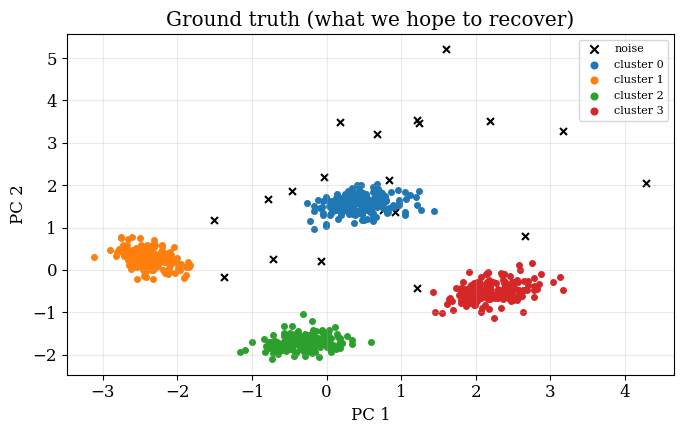

In [ ]:
X = df[features].values
y_true_label = df["true_segment"].values

# ground-truth numeric labels; outliers = -1 (so external metrics can use them)
seg_to_id = {s: i for i, s in enumerate(
    ["Premium Loyalists", "Young Trend Shoppers", "Budget Conscious", "Affluent Infrequent"])}
y_true = np.array([seg_to_id.get(s, -1) for s in y_true_label])

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)
print("Variance explained by 2 PCs:", pca.explained_variance_ratio_.round(3),
      " (sum =", round(pca.explained_variance_ratio_.sum(), 3), ")")

def plot_clusters(labels, title, ax=None):
    ax = ax or plt.gca()
    uniq = sorted(set(labels))
    for lb in uniq:
        m = labels == lb
        if lb == -1:
            ax.scatter(X_pca[m,0], X_pca[m,1], c="black", marker="x", s=25, label="noise")
        else:
            ax.scatter(X_pca[m,0], X_pca[m,1], s=16, label=f"cluster {lb}")
    ax.set_xlabel("PC 1"); ax.set_ylabel("PC 2"); ax.set_title(title)
    ax.legend(fontsize=8, markerscale=1.2)

plt.figure()
plot_clusters(y_true, "Ground truth (what we hope to recover)")
plt.tight_layout(); plt.show()

## 6 · K-Means

K-Means needs the number of clusters **k** up front. Two standard tools to choose it:
the **elbow** (inertia = within-cluster sum of squares) and the **silhouette** score.

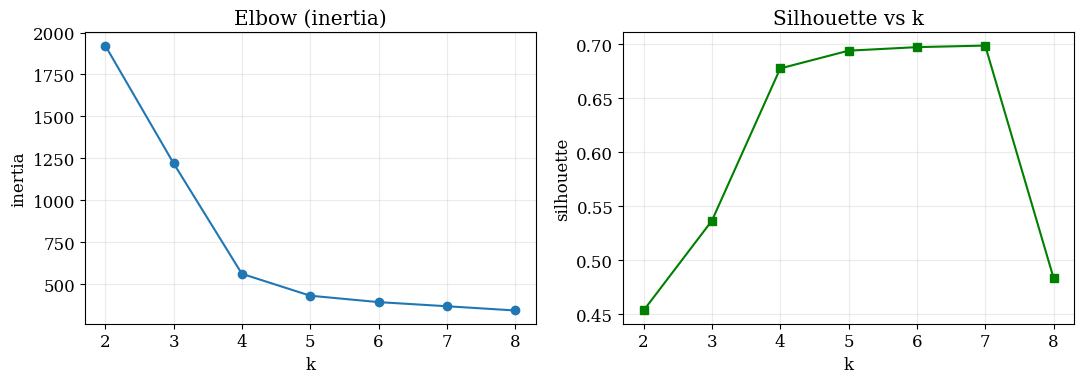

silhouette by k: {2: np.float64(0.453), 3: np.float64(0.537), 4: np.float64(0.678), 5: np.float64(0.694), 6: np.float64(0.697), 7: np.float64(0.699), 8: np.float64(0.484)}


In [ ]:
ks = range(2, 9)
inertias, sils = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_scaled)
    inertias.append(km.inertia_)
    sils.append(silhouette_score(X_scaled, km.labels_))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(list(ks), inertias, "o-"); ax[0].set_title("Elbow (inertia)")
ax[0].set_xlabel("k"); ax[0].set_ylabel("inertia")
ax[1].plot(list(ks), sils, "s-", color="green"); ax[1].set_title("Silhouette vs k")
ax[1].set_xlabel("k"); ax[1].set_ylabel("silhouette")
plt.tight_layout(); plt.show()
print("silhouette by k:", dict(zip(ks, np.round(sils, 3))))

The inertia curve bends sharply at **k = 4** (big drop up to 4, nearly flat after). Silhouette jumps to ~0.68
at k = 4 and is essentially flat beyond it — the small gains at k = 5–7 split real segments into pieces. Elbow +
interpretability ⇒ **k = 4**.

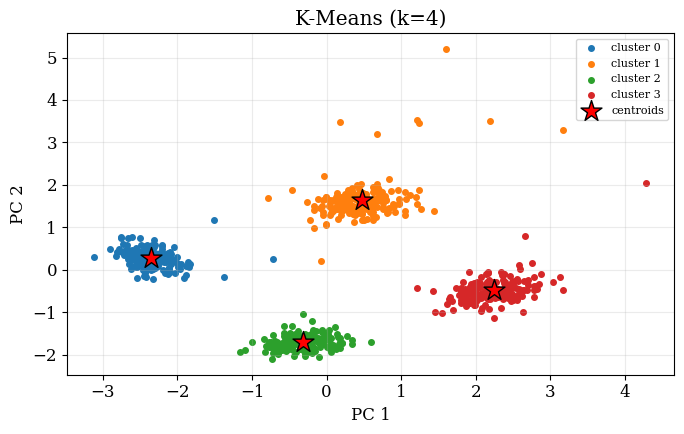

In [ ]:
kmeans = KMeans(n_clusters=4, n_init=10, random_state=RANDOM_STATE)
labels_kmeans = kmeans.fit_predict(X_scaled)

plt.figure()
plot_clusters(labels_kmeans, "K-Means (k=4)")
# project centroids into PCA space
cent = pca.transform(kmeans.cluster_centers_)
plt.scatter(cent[:,0], cent[:,1], c="red", marker="*", s=250, edgecolor="k", label="centroids")
plt.legend(fontsize=8); plt.tight_layout(); plt.show()

## 7 · Hierarchical (Agglomerative)

Build the merge tree with **Ward linkage** and inspect the **dendrogram**. With 680 points we show the top of the
tree (`truncate_mode="lastp"`) so it stays readable.

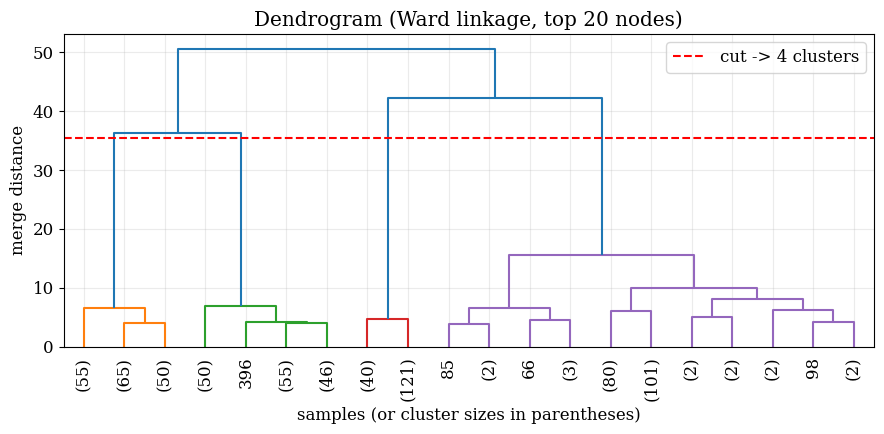

In [ ]:
Z = linkage(X_scaled, method="ward")

plt.figure(figsize=(9, 4.5))
dendrogram(Z, truncate_mode="lastp", p=20, leaf_rotation=90, color_threshold=0.7*np.max(Z[:,2]))
plt.axhline(0.7*np.max(Z[:,2]), color="red", ls="--", lw=1.5, label="cut -> 4 clusters")
plt.title("Dendrogram (Ward linkage, top 20 nodes)")
plt.xlabel("samples (or cluster sizes in parentheses)"); plt.ylabel("merge distance")
plt.legend(); plt.tight_layout(); plt.show()

The largest vertical gap sits just below the top — cutting there yields **4 clusters**, matching K-Means.

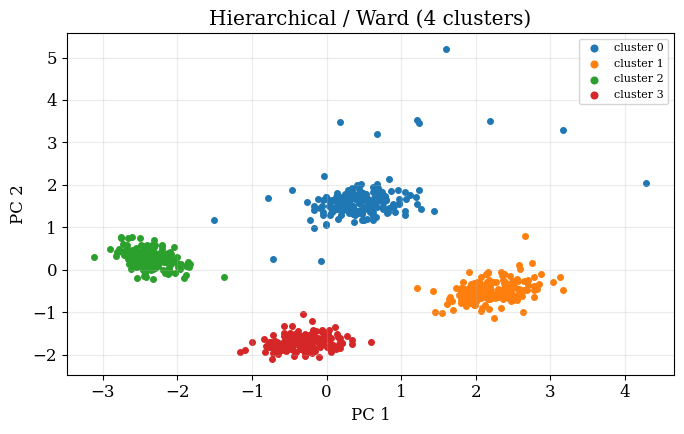

In [ ]:
agg = AgglomerativeClustering(n_clusters=4, linkage="ward")
labels_agg = agg.fit_predict(X_scaled)

plt.figure()
plot_clusters(labels_agg, "Hierarchical / Ward (4 clusters)")
plt.tight_layout(); plt.show()

## 8 · DBSCAN

DBSCAN needs **ε** (radius) and **min_samples**. Rule of thumb for min_samples ≈ 2 × dimensions, so we use
**10**. For ε we read the **k-distance graph**: sort every point's distance to its 10th-nearest neighbour and
look for the *knee* where the curve turns sharply up.

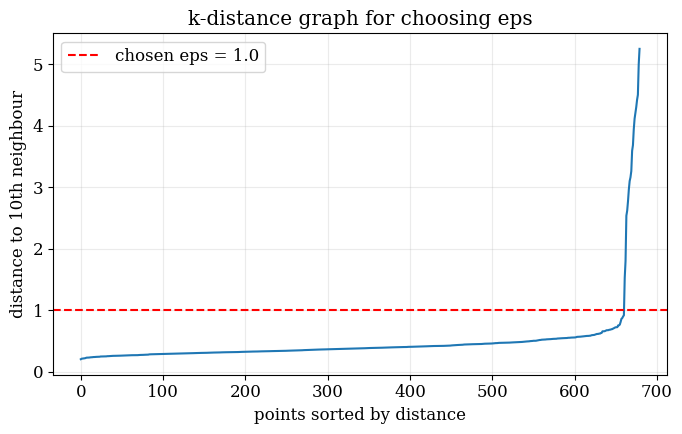

In [ ]:
min_samples = 10
nn = NearestNeighbors(n_neighbors=min_samples).fit(X_scaled)
dist, _ = nn.kneighbors(X_scaled)
k_dist = np.sort(dist[:, -1])

plt.figure()
plt.plot(k_dist)
plt.axhline(1.0, color="red", ls="--", label="chosen eps = 1.0")
plt.xlabel("points sorted by distance"); plt.ylabel(f"distance to {min_samples}th neighbour")
plt.title("k-distance graph for choosing eps"); plt.legend(); plt.tight_layout(); plt.show()

The curve is flat for the dense segment points and then shoots up for the sparse outliers — the knee is near
**ε = 1.0**. Below the knee, dense points keep their cluster; above it, the sparse outliers are cut off as noise.

DBSCAN found 4 clusters and flagged 19 points as noise.


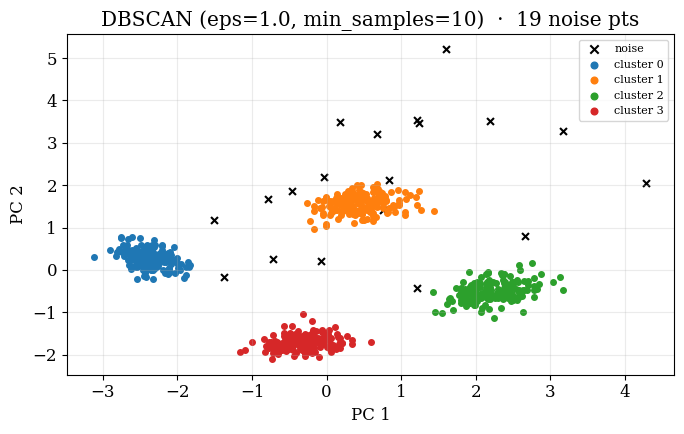

In [ ]:
dbscan = DBSCAN(eps=1.0, min_samples=min_samples)
labels_dbscan = dbscan.fit_predict(X_scaled)

n_clusters = len(set(labels_dbscan)) - (1 if -1 in labels_dbscan else 0)
n_noise = int((labels_dbscan == -1).sum())
print(f"DBSCAN found {n_clusters} clusters and flagged {n_noise} points as noise.")

plt.figure()
plot_clusters(labels_dbscan, f"DBSCAN (eps=1.0, min_samples=10)  ·  {n_noise} noise pts")
plt.tight_layout(); plt.show()

DBSCAN recovers the four dense segments **and** isolates the injected outliers as noise (label −1) — something
neither K-Means nor hierarchical can do, since they force every point into a cluster.

## 9 · Evaluation metrics

Two families:

**Internal** (no ground truth — measure cluster *shape*; higher silhouette & Calinski–Harabasz are better,
*lower* Davies–Bouldin is better):
- `silhouette` ∈ [−1, 1] — how tight vs. separated clusters are
- `davies_bouldin` ≥ 0 — average similarity of each cluster to its closest other (lower = better)
- `calinski_harabasz` — between/within dispersion ratio (higher = better)

**External** (compare to the known segments; all ∈ [0, 1], higher = better):
- `ARI` — Adjusted Rand Index (chance-corrected agreement)
- `NMI` — Normalised Mutual Information
- `V_measure` — harmonic mean of homogeneity & completeness

For DBSCAN we compute **internal** metrics on the clustered points only (noise excluded), but **external** metrics
on all points — correctly identifying outliers should count in its favour.

In [ ]:
def evaluate(labels, name):
    core = labels != -1                      # exclude noise for internal metrics
    row = {"method": name,
           "n_clusters": len(set(labels)) - (1 if -1 in labels else 0),
           "noise_pts": int((labels == -1).sum())}
    if len(set(labels[core])) > 1:
        row["silhouette"]       = round(silhouette_score(X_scaled[core], labels[core]), 3)
        row["davies_bouldin"]   = round(davies_bouldin_score(X_scaled[core], labels[core]), 3)
        row["calinski_harabasz"]= round(calinski_harabasz_score(X_scaled[core], labels[core]), 0)
    row["ARI"]       = round(adjusted_rand_score(y_true, labels), 3)
    row["NMI"]       = round(normalized_mutual_info_score(y_true, labels), 3)
    row["V_measure"] = round(homogeneity_completeness_v_measure(y_true, labels)[2], 3)
    return row

results = pd.DataFrame([
    evaluate(labels_kmeans, "K-Means"),
    evaluate(labels_agg,    "Hierarchical"),
    evaluate(labels_dbscan, "DBSCAN"),
]).set_index("method")
results

,n_clusters,noise_pts,silhouette,davies_bouldin,calinski_harabasz,ARI,NMI,V_measure
method,,,,,,,,
K-Means,4,0,0.678,0.494,1141.0,0.958,0.950,0.950
Hierarchical,4,0,0.676,0.501,1115.0,0.958,0.956,0.956
DBSCAN,4,19,0.721,0.411,2501.0,0.998,0.995,0.995


All three recover the four segments with high agreement. K-Means and hierarchical are
nearly tied. **DBSCAN scores highest on the external metrics (ARI/NMI/V)** because it also strips out the 19
outliers that the other two are forced to misassign, and it posts the best internal scores too, since its clusters
are the cleanest once noise is removed. The lesson: the *right* metric depends on whether outlier handling matters
for your problem.

## 10 · Profile the clusters (what do they mean?)

Metrics tell us the clusters are *good*; profiling tells us what they *are*. We attach the K-Means labels back to
the **original (un-scaled) features** and read each cluster's averages.

In [ ]:
prof = df.copy()
prof["cluster"] = labels_kmeans
summary = prof.groupby("cluster")[features].mean().round(1)
summary["size"] = prof.groupby("cluster").size()
summary

,age,annual_income_k,spending_score,web_sessions_mo,avg_purchase_usd,size
cluster,,,,,,
0,25.3,37.9,77.5,41.9,41.9,163
1,45.2,84.8,80.0,27.2,130.1,194
2,36.5,42.9,28.1,11.2,28.0,170
3,54.4,99.0,22.7,5.3,91.5,153


In [ ]:
# cross-check: how do K-Means clusters line up with the true segments?
pd.crosstab(prof["cluster"], prof["true_segment"])

true_segment,Affluent Infrequent,Budget Conscious,Outlier,Premium Loyalists,Young Trend Shoppers
cluster,,,,,
0,0,0,3,0,160
1,0,0,14,180,0
2,0,170,0,0,0
3,150,0,3,0,0


Each discovered cluster maps cleanly onto one real persona, e.g. the cluster with high income, high spend and
many sessions is the *Premium Loyalists*. This is how segmentation turns into action (targeting, pricing, retention).

## 11 · Conclusion & exercises

**What we did** — built a realistic 5-feature customer dataset with outliers; scaled it; chose parameters properly
(elbow/silhouette for k, dendrogram cut, k-distance for ε); ran K-Means, hierarchical and DBSCAN; and scored them
with internal *and* external metrics.

**Takeaways**
- K-Means & hierarchical both recovered the 4 segments and agreed closely.
- DBSCAN matched them **and** isolated the outliers — winning the external metrics — but needed ε tuned.
- Always **scale** features, and **validate** the cluster count rather than guessing it.

**Exercises**
1. Change `spread` in `make_segment` to `1.3` (more overlap). Which method degrades first? Watch ARI.
2. Re-run DBSCAN with `eps = 0.6` and `eps = 1.6`. Explain the cluster/noise counts using the k-distance graph.
3. Drop `annual_income_k` before scaling — does any method lose a segment?
4. Add `AgglomerativeClustering(..., linkage="single")` and compare its metrics to Ward. Why the difference?
5. Load a real dataset (e.g. `sklearn.datasets.load_wine`) and repeat the whole pipeline.

---



# **Thank You!!**